# 1. Feature Engineering & Setup

In [3]:
%pip install pyclustering optuna numpy matplotlib scikit-learn hdbscan pandas

     ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
      --------------------------------------- 0.1/11.3 MB 4.3 MB/s eta 0:00:03
     - -------------------------------------- 0.4/11.3 MB 5.5 MB/s eta 0:00:02
     -- ------------------------------------- 0.8/11.3 MB 6.1 MB/s eta 0:00:02
     ---- ----------------------------------- 1.2/11.3 MB 6.8 MB/s eta 0:00:02
     ----- ---------------------------------- 1.7/11.3 MB 7.6 MB/s eta 0:00:02
     ------- -------------------------------- 2.2/11.3 MB 8.4 MB/s eta 0:00:02
     ---------- ----------------------------- 2.9/11.3 MB 9.3 MB/s eta 0:00:01
     ------------ --------------------------- 3.6/11.3 MB 10.1 MB/s eta 0:00:01
     --------------- ------------------------ 4.5/11.3 MB 11.1 MB/s eta 0:00:01
     ------------------- -------------------- 5.6/11.3 MB 12.3 MB/s eta 0:00:01
     ------------------------ --------------- 6.8/11.3 MB 13.6 MB/s eta 0:00:01
     ----------------------------- ---------- 8.3/11.3 


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import math
import os
import glob
import json
from collections import defaultdict, Counter
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score, adjusted_mutual_info_score
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.impute import SimpleImputer
import optuna
from pyclustering.cluster.clarans import clarans

labels_folder = "data/Merged_labels"
use_feature_engineering = True

rivers_df = pd.read_csv("data/rivers.csv", sep=';')

# Original Features
features_base = ["DIST_DN_KM", "DIS_AV_CMS", "ORD_CLAS", "ORD_FLOW", "ORD_STRA", "DIST_UP_KM", "UPLAND_SKM", "CATCH_SKM"]

# Only keeping ID and base features
rivers_features = rivers_df[["HYRIV_ID"] + features_base].copy()

def engineer_features(df):
    df = df.copy()
    epsilon = 1e-5
    df['NET_LENGTH'] = df['DIST_UP_KM'] + df['DIST_DN_KM']
    df['ORDER_RATIO'] = df['ORD_FLOW'] / (df['ORD_CLAS'] + epsilon)
    df['LENGTH_OVER_ORDER'] = df['NET_LENGTH'] / (df['ORD_FLOW'] + epsilon)
    df['UPLAND_DENSITY'] = df['UPLAND_SKM'] / (df['DIS_AV_CMS'] + epsilon)
    return df

rivers_features = engineer_features(rivers_features)
features = ["DIST_DN_KM", "NET_LENGTH", "ORDER_RATIO", "LENGTH_OVER_ORDER", "UPLAND_DENSITY"]

# Preprocessing
data_array_raw = rivers_features[features].values
ids_raw = rivers_features["HYRIV_ID"].values 

# 1. Imputation
imputer = SimpleImputer(strategy="mean")
data_array_imputed = imputer.fit_transform(data_array_raw)

# 2. Scaling (PowerTransformer to handle outliers)
scaler = PowerTransformer()
clean_scaled_data = scaler.fit_transform(data_array_imputed)

print(f"Dataset shape after preprocessing: {clean_scaled_data.shape}")

c:\Users\clado\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset shape after preprocessing: (57082, 5)


# 2. Support Metrics

In [5]:
def calculate_distance(point, centroid):
    return math.sqrt(sum((p - c) ** 2 for p, c in zip(point, centroid)))

def calculate_dunn_index(data, labels, centroids):
    if len(centroids) < 2:
        return 0.0

    inter_cluster_distances = pdist(centroids)
    if len(inter_cluster_distances) == 0: return 0.0
    min_inter_cluster_distance = np.min(inter_cluster_distances)

    max_intra_cluster_diameter = 0
    unique_labels = np.unique(labels)

    for i in unique_labels:
        cluster_points = data[labels == i]
        if len(cluster_points) > 1:
            intra_distances = pdist(cluster_points)
            if len(intra_distances) > 0:
                max_diameter = np.max(intra_distances)
                if max_diameter > max_intra_cluster_diameter:
                    max_intra_cluster_diameter = max_diameter

    if max_intra_cluster_diameter == 0:
        return 0.0

    return min_inter_cluster_distance / max_intra_cluster_diameter

# 3. Grid Search with Optuna (K-Means & CLARANS)

In [6]:
import warnings
import time
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import optuna

warnings.filterwarnings('ignore')

k = 7

# ==============================================================================
# OPTIMIZED CLARANS (Vectorialized in NumPy)
# ==============================================================================
def fast_clarans(data, k, numlocal=3, maxneighbor=30, random_state=42):
    rng = np.random.default_rng(random_state)
    n_samples = len(data)
    best_medoids = None
    best_cost = float('inf')
    
    for _ in range(numlocal):
        current_medoids = rng.choice(n_samples, size=k, replace=False)
        dists = np.sum((data[:, np.newaxis, :] - data[current_medoids])**2, axis=2)
        current_cost = np.sum(np.min(dists, axis=1))
        
        count = 0
        while count < maxneighbor:
            medoid_idx = rng.integers(0, k)
            candidate = rng.integers(0, n_samples)
            while candidate in current_medoids:
                candidate = rng.integers(0, n_samples)
            
            cand_dist = np.sum((data - data[candidate])**2, axis=1)
            
            mask = np.ones(k, dtype=bool)
            mask[medoid_idx] = False
            other_min_dist = np.min(dists[:, mask], axis=1)
            new_cost = np.sum(np.minimum(other_min_dist, cand_dist))
            
            if new_cost < current_cost:
                current_cost = new_cost
                current_medoids[medoid_idx] = candidate
                dists[:, medoid_idx] = cand_dist
                count = 0
            else:
                count += 1
                
        if current_cost < best_cost:
            best_cost = current_cost
            best_medoids = current_medoids.copy()
            
    final_dists = np.sum((data[:, np.newaxis, :] - data[best_medoids])**2, axis=2)
    labels = np.argmin(final_dists, axis=1)
    centroids = data[best_medoids]
    return labels, centroids, best_medoids

# ==============================================================================
# 1. K-Means Tuning
# ==============================================================================
print("--- Starting Tuning K-Means ---")

def objective_kmeans(trial):
    init = trial.suggest_categorical('init', ['k-means++', 'random'])
    n_init = trial.suggest_int('n_init', 10, 30)
    
    kmeans = KMeans(n_clusters=k, init=init, n_init=n_init, random_state=42)
    labels = kmeans.fit_predict(clean_scaled_data)
    
    # sample_size=10000 accelera in modo impressionante il calcolo della 
    # Silhouette, che altrimenti frena Optuna inutilmente.
    score = silhouette_score(clean_scaled_data, labels, sample_size=10000, random_state=42)
    return score

study_kmeans = optuna.create_study(direction='maximize')
study_kmeans.optimize(objective_kmeans, n_trials=10) # 10 trial
print("Best parameters for K-Means:", study_kmeans.best_params)


# ==============================================================================
# 2. CLARANS Tuning (Vectorialized)
# ==============================================================================
print("\n--- Starting Tuning CLARANS ---")
np.random.seed(42)
sample_indices = np.random.choice(len(clean_scaled_data), size=5000, replace=False)
clarans_sample = clean_scaled_data[sample_indices]

def objective_clarans(trial):
    numlocal = trial.suggest_int('numlocal', 2, 5)
    maxneighbor = trial.suggest_int('maxneighbor', 20, 100)
    
    labels, centroids, medoids = fast_clarans(
        data=clarans_sample, 
        k=k, 
        numlocal=numlocal, 
        maxneighbor=maxneighbor,
        random_state=42
    )
    
    if len(set(labels)) > 1:
        return silhouette_score(clarans_sample, labels)
    return -1

study_clarans = optuna.create_study(direction='maximize')
study_clarans.optimize(objective_clarans, n_trials=30) 
print("Best parameters for CLARANS:", study_clarans.best_params)


[I 2026-10-07 18:07:05,008] A new study created in memory with name: no-name-1672632d-4559-4f43-a0fe-341df8ee6c07


--- Starting Tuning K-Means ---


[I 2026-10-07 18:07:06,694] Trial 0 finished with value: 0.29701376022645065 and parameters: {'init': 'k-means++', 'n_init': 10}. Best is trial 0 with value: 0.29701376022645065.
[I 2026-10-07 18:07:08,456] Trial 1 finished with value: 0.2970070398072043 and parameters: {'init': 'k-means++', 'n_init': 21}. Best is trial 0 with value: 0.29701376022645065.
[I 2026-10-07 18:07:10,092] Trial 2 finished with value: 0.2970070398072043 and parameters: {'init': 'k-means++', 'n_init': 19}. Best is trial 0 with value: 0.29701376022645065.
[I 2026-10-07 18:07:11,719] Trial 3 finished with value: 0.2970070398072043 and parameters: {'init': 'k-means++', 'n_init': 15}. Best is trial 0 with value: 0.29701376022645065.
[I 2026-10-07 18:07:13,146] Trial 4 finished with value: 0.2970070398072043 and parameters: {'init': 'k-means++', 'n_init': 12}. Best is trial 0 with value: 0.29701376022645065.
[I 2026-10-07 18:07:14,649] Trial 5 finished with value: 0.29701474574780384 and parameters: {'init': 'random

Best parameters for K-Means: {'init': 'random', 'n_init': 18}

--- Starting Tuning CLARANS ---


[I 2026-10-07 18:07:20,953] Trial 0 finished with value: 0.2828372332494496 and parameters: {'numlocal': 5, 'maxneighbor': 75}. Best is trial 0 with value: 0.2828372332494496.
[I 2026-10-07 18:07:21,319] Trial 1 finished with value: 0.26579625923495076 and parameters: {'numlocal': 3, 'maxneighbor': 81}. Best is trial 0 with value: 0.2828372332494496.
[I 2026-10-07 18:07:21,677] Trial 2 finished with value: 0.26609648948417913 and parameters: {'numlocal': 3, 'maxneighbor': 61}. Best is trial 0 with value: 0.2828372332494496.
[I 2026-10-07 18:07:22,027] Trial 3 finished with value: 0.2570763698599704 and parameters: {'numlocal': 5, 'maxneighbor': 33}. Best is trial 0 with value: 0.2828372332494496.
[I 2026-10-07 18:07:22,387] Trial 4 finished with value: 0.26579625923495076 and parameters: {'numlocal': 2, 'maxneighbor': 70}. Best is trial 0 with value: 0.2828372332494496.
[I 2026-10-07 18:07:22,735] Trial 5 finished with value: 0.2459198810110801 and parameters: {'numlocal': 2, 'maxneigh

Best parameters for CLARANS: {'numlocal': 4, 'maxneighbor': 99}


# 4. Model Execution with Optimized Parameters

In [7]:
import time
import numpy as np
from sklearn.cluster import KMeans

# ==============================================================================
# 1. FUNZIONE CLARANS OPTIMIZED (according to Ng & Han 1994)
# ==============================================================================
def fast_clarans(data, k, numlocal=1, maxneighbor=15, random_state=42):
    """
    Vectorialized CLARANS implementation to handle optimized parameters found by Optuna
    """
    rng = np.random.default_rng(random_state)
    n_samples = len(data)
    best_medoids = None
    best_cost = float('inf')
    
    for _ in range(numlocal):
        current_medoids = rng.choice(n_samples, size=k, replace=False)
        dists = np.sum((data[:, np.newaxis, :] - data[current_medoids])**2, axis=2)
        current_cost = np.sum(np.min(dists, axis=1))
        
        count = 0
        while count < maxneighbor:
            medoid_idx = rng.integers(0, k)
            candidate = rng.integers(0, n_samples)
            while candidate in current_medoids:
                candidate = rng.integers(0, n_samples)
            
            cand_dist = np.sum((data - data[candidate])**2, axis=1)
            
            mask = np.ones(k, dtype=bool)
            mask[medoid_idx] = False
            other_min_dist = np.min(dists[:, mask], axis=1)
            new_cost = np.sum(np.minimum(other_min_dist, cand_dist))
            
            if new_cost < current_cost:
                current_cost = new_cost
                current_medoids[medoid_idx] = candidate
                dists[:, medoid_idx] = cand_dist
                count = 0
            else:
                count += 1
                
        if current_cost < best_cost:
            best_cost = current_cost
            best_medoids = current_medoids.copy()
            
    final_dists = np.sum((data[:, np.newaxis, :] - data[best_medoids])**2, axis=2)
    labels = np.argmin(final_dists, axis=1)
    centroids = data[best_medoids]
    return labels, centroids, best_medoids


# ==============================================================================
# 2. K-MEANS EXECUTION (with Optuna parameters)
# ==============================================================================
best_kmeans_params = study_kmeans.best_params
print("Parameters for K-Means (Optuna):", best_kmeans_params)

t0_km = time.time()
kmeans = KMeans(n_clusters=k, random_state=42, **best_kmeans_params)
kmeans_labels = kmeans.fit_predict(clean_scaled_data)
kmeans_centroids = kmeans.cluster_centers_
print(f"K-Means completed in {time.time() - t0_km:.2f} s")


# ==============================================================================
# 3. CLARANS EXECUTION (with Optuna parameters)
# ==============================================================================
best_clarans_params = study_clarans.best_params
print("\nParameters for CLARANS (Optuna):", best_clarans_params)

t0_cl = time.time()
clarans_labels, clarans_centroids, clarans_medoids = fast_clarans(
    data=clean_scaled_data,
    k=k,
    random_state=42,
    **best_clarans_params
)
print(f"CLARANS completed in {time.time() - t0_cl:.2f} s")
print(f"Assigned points: {len(clarans_labels)}, identified clusters: {len(np.unique(clarans_labels))}")


Parameters for K-Means (Optuna): {'init': 'random', 'n_init': 18}
K-Means completed in 0.32 s

Parameters for CLARANS (Optuna): {'numlocal': 4, 'maxneighbor': 99}
CLARANS completed in 2.61 s
Assigned points: 57082, identified clusters: 7


In [14]:
import os
import glob
import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment

# ==============================================================================
# 4. Cluster MAPPING -> Classes found in Merged_labels (1-to-1 Exact)
# ==============================================================================
print("\n--- Clusters Mapping -> Classes Names (1-to-1) ---")
labels_folder = "data/Merged_labels"
labelled_dfs = []

for file in glob.glob(f"{labels_folder}/*.csv"):
    if file.lower() == "data/rivers.csv": continue
    class_name = os.path.splitext(os.path.basename(file))[0].capitalize()
    df = pd.read_csv(file, sep=';')
    df = df[["HYRIV_ID"]].copy()
    df["True_Label"] = class_name
    labelled_dfs.append(df)

if labelled_dfs:
    true_labels_df = pd.concat(labelled_dfs, ignore_index=True)
    
    results_df = pd.DataFrame({
        "HYRIV_ID": ids_raw, 
        "KMeans_Cluster": kmeans_labels, 
        "CLARANS_Cluster": clarans_labels
    })
    mapped_df = pd.merge(results_df, true_labels_df, on="HYRIV_ID", how="inner")
    
    unique_classes = sorted(true_labels_df["True_Label"].unique())
    n_classes = len(unique_classes)
    
    def get_1to1_mapping(cluster_col):
        cost_matrix = np.zeros((k, n_classes))
        for i in range(k):
            for j, cls_name in enumerate(unique_classes):
                count = len(mapped_df[(mapped_df[cluster_col] == i) & (mapped_df["True_Label"] == cls_name)])
                cost_matrix[i, j] = -count 
                
        row_ind, col_ind = linear_sum_assignment(cost_matrix)
        
        mapping = {}
        for r, c in zip(row_ind, col_ind):
            mapping[r] = unique_classes[c]
        return mapping
        
    kmeans_cluster_names = get_1to1_mapping("KMeans_Cluster")
    clarans_cluster_names = get_1to1_mapping("CLARANS_Cluster")
    
    print(f"Total classes in Merged_labels: {n_classes} | K set to: {k}\n")
    print("K-Means Mapping:", kmeans_cluster_names)
    print("CLARANS Mapping:", clarans_cluster_names)
else:
    print("No file found in Merged_labels.")
    kmeans_cluster_names = {i: f"Cluster {i}" for i in range(k)}
    clarans_cluster_names = {i: f"Cluster {i}" for i in range(k)}



--- Clusters Mapping -> Classes Names (1-to-1) ---
Total classes in Merged_labels: 7 | K set to: 7

K-Means Mapping: {np.int64(0): 'Trellis', np.int64(1): 'Pinnate', np.int64(2): 'Dendritic', np.int64(3): 'Angular', np.int64(4): 'Rectangular', np.int64(5): 'Sub-dendritic', np.int64(6): 'Parallel'}
CLARANS Mapping: {np.int64(0): 'Rectangular', np.int64(1): 'Dendritic', np.int64(2): 'Angular', np.int64(3): 'Pinnate', np.int64(4): 'Trellis', np.int64(5): 'Sub-dendritic', np.int64(6): 'Parallel'}


# 5. Model Evaluation (Metrics)

In [9]:
%pip install hdbscan

Note: you may need to restart the kernel to use updated packages.Requirement already satisfied: hdbscan in c:\users\clado\appdata\local\programs\python\python310\lib\site-packages (0.8.44)




[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


--- Metrics for K-Means ---
Silhouette: 0.2984
Davies-Bouldin: 1.0988
Dunn Index: 0.2124
--- Metrics for CLARANS ---
Silhouette: 0.2737
Davies-Bouldin: 1.1331
Dunn Index: 0.2008


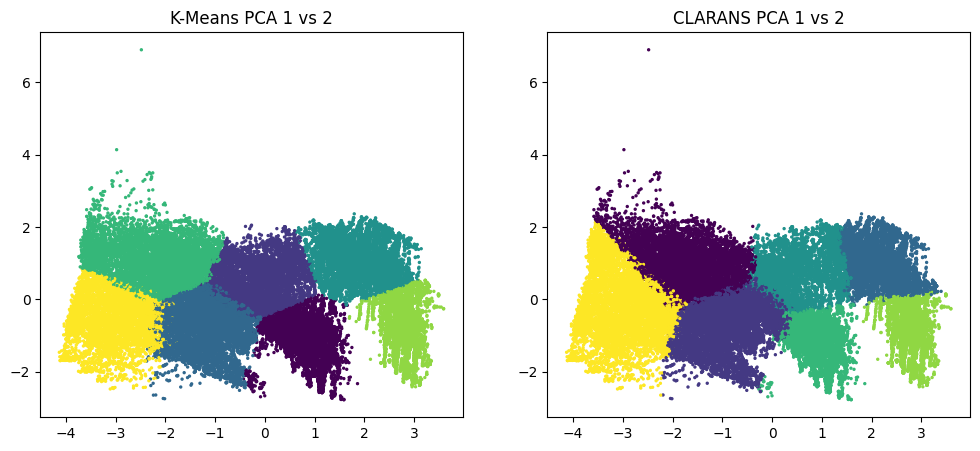

In [10]:
def print_metrics(name, data, labels, centroids):
    sil = silhouette_score(data, labels)
    db = davies_bouldin_score(data, labels)
    dunn = calculate_dunn_index(data, labels, centroids)
    print(f"--- Metrics for {name} ---")
    print(f"Silhouette: {sil:.4f}")
    print(f"Davies-Bouldin: {db:.4f}")
    print(f"Dunn Index: {dunn:.4f}")


print_metrics("K-Means", clean_scaled_data, kmeans_labels, kmeans_centroids)
print_metrics("CLARANS", clean_scaled_data, clarans_labels, clarans_centroids)

pca = PCA(n_components=3)
cspdata = pca.fit_transform(clean_scaled_data)

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
axs[0].scatter(cspdata[:, 0], cspdata[:, 1], c=kmeans_labels, cmap='viridis', s=2)
axs[0].set_title('K-Means PCA 1 vs 2')

axs[1].scatter(cspdata[:, 0], cspdata[:, 1], c=clarans_labels, cmap='viridis', s=2)
axs[1].set_title('CLARANS PCA 1 vs 2')
plt.show()

# 6. Test on Unseen Elements (Bulk Classification)

In [11]:
test_items_path = "data/test_items"

active_model = kmeans

print(f"Starting bulk classification from {test_items_path}...")
files = sorted([f for f in os.listdir(test_items_path) if f.endswith(".csv") and "NEW" not in f])

for file_name in files:
    file_path = os.path.join(test_items_path, file_name)
    df_test = pd.read_csv(file_path, sep=';')
    if use_feature_engineering:
        df_test = engineer_features(df_test)
        
    X_test = scaler.transform(imputer.transform(df_test[features].values))
    segment_clusters = active_model.predict(X_test)

    # Majority vote
    from collections import Counter
    counts = Counter(segment_clusters)
    most_common_cluster, max_count = counts.most_common(1)[0]
    percentage = (max_count / len(segment_clusters)) * 100

    cluster_name = kmeans_cluster_names.get(most_common_cluster, f"Cluster {most_common_cluster}")
    print(f"{file_name}: Assigned to '{cluster_name}' by majority vote (Votes: {percentage:.1f}%)\n")


Starting bulk classification from data/test_items...
Adige_angular.csv: Assigned to 'Trellis' by majority vote (Votes: 55.0%)

Amazon_dendritic.csv: Assigned to 'Sub-dendritic' by majority vote (Votes: 61.4%)

Brenta_trellis.csv: Assigned to 'Dendritic' by majority vote (Votes: 83.1%)

Ebro_pinnate.csv: Assigned to 'Trellis' by majority vote (Votes: 39.1%)

Garonne_angular.csv: Assigned to 'Trellis' by majority vote (Votes: 49.0%)

Po_pinnate.csv: Assigned to 'Trellis' by majority vote (Votes: 91.2%)

Rhine_dendritic.csv: Assigned to 'Pinnate' by majority vote (Votes: 50.2%)

Seine_Angular.csv: Assigned to 'Pinnate' by majority vote (Votes: 52.2%)

Thames_dendritic.csv: Assigned to 'Pinnate' by majority vote (Votes: 86.4%)

Tiber_dendritic.csv: Assigned to 'Pinnate' by majority vote (Votes: 58.9%)

Volturno_trellis.csv: Assigned to 'Dendritic' by majority vote (Votes: 64.9%)

Yangtze_Pinnate.csv: Assigned to 'Trellis' by majority vote (Votes: 82.2%)



# 7. Reduction to Desired Class and Delta computing (Error)

In [12]:
def get_river_representation(df, features, scaler, imputer):
    X_raw = df[features].values
    X_raw = imputer.transform(X_raw)
    river_mean = np.mean(X_raw, axis=0).reshape(1, -1)
    return scaler.transform(river_mean)

def correct_river_class(csv_path, target_cluster_id, active_model):
    df = pd.read_csv(csv_path, sep=';')
    if use_feature_engineering: df = engineer_features(df)
        
    target_centroid = active_model.cluster_centers_[target_cluster_id].reshape(1, -1)
    best_dist = float('inf')
    
    for _ in range(50):
        current_vec = get_river_representation(df, features, scaler, imputer)
        current_cluster = active_model.predict(current_vec)[0]
        
        if current_cluster == target_cluster_id or len(df) < 3:
            break
            
        X_segments = scaler.transform(imputer.transform(df[features].values))
        current_sum = np.sum(X_segments, axis=0)
        n = len(df)
        
        new_means = (current_sum - X_segments) / (n - 1)
        dists = np.linalg.norm(new_means - target_centroid, axis=1)
        
        best_idx = np.argmin(dists)
        if dists[best_idx] >= best_dist:
            break
            
        best_dist = dists[best_idx]
        df = df.drop(df.index[best_idx]).reset_index(drop=True)
        
    return df


inverse_kmeans_cluster_names = {v: k for k, v in kmeans_cluster_names.items()}

print("\n--- Computing Delta (Error) for each river, considering actual classes ---")
for file_name in files:
    original_path = os.path.join(test_items_path, file_name)
    true_class = file_name.split('_')[-1].replace('.csv', '').capitalize()
    if true_class not in inverse_kmeans_cluster_names:
        print(f"{file_name} -> WARNING: Actual class '{true_class}' not found in K-Means mapping!")
        continue
    target_id = inverse_kmeans_cluster_names[true_class]
    target_name = kmeans_cluster_names.get(target_id, f"Cluster {target_id}")
    
    # 1. Original distance
    df_orig = pd.read_csv(original_path, sep=';')
    if use_feature_engineering: df_orig = engineer_features(df_orig)
    vec_orig = get_river_representation(df_orig, features, scaler, imputer)
    dist_orig = np.linalg.norm(vec_orig - kmeans.cluster_centers_[target_id])
    
    # 2. Distance after correction
    df_new = correct_river_class(original_path, target_id, kmeans)
    vec_new = get_river_representation(df_new, features, scaler, imputer)
    dist_new = np.linalg.norm(vec_new - kmeans.cluster_centers_[target_id])
    
    delta = dist_orig - dist_new
    print(f"{file_name} -> Delta (Distance improving towards '{target_name}'): {delta:.4f}")



--- Computing Delta (Error) for each river, considering actual classes ---
Adige_angular.csv -> Delta (Distance improving towards 'Angular'): 0.0149
Amazon_dendritic.csv -> Delta (Distance improving towards 'Dendritic'): 0.0091
Brenta_trellis.csv -> Delta (Distance improving towards 'Trellis'): 0.2884
Ebro_pinnate.csv -> Delta (Distance improving towards 'Pinnate'): 0.0170
Garonne_angular.csv -> Delta (Distance improving towards 'Angular'): 0.0181
Po_pinnate.csv -> Delta (Distance improving towards 'Pinnate'): 0.0090
Rhine_dendritic.csv -> Delta (Distance improving towards 'Dendritic'): 0.1159
Seine_Angular.csv -> Delta (Distance improving towards 'Angular'): 0.0741
Thames_dendritic.csv -> Delta (Distance improving towards 'Dendritic'): 0.0536
Tiber_dendritic.csv -> Delta (Distance improving towards 'Dendritic'): 0.0797
Volturno_trellis.csv -> Delta (Distance improving towards 'Trellis'): 0.1034
Yangtze_Pinnate.csv -> Delta (Distance improving towards 'Pinnate'): 0.0138
